# 곁(GYEOT) v5 — 판단력 저하를 거래 패턴의 장기 변화로 감지

v2~v4는 **사기 사건**을 잡았다. 며칠 안에 터지는 이상 거래다. 그런데 노인의 금융 위험에는 다른 모양이 있다. 경도인지장애·치매 초기에는 거래 하나하나는 정상이지만, **이 사람의 1년 전과 지금이 다르다.** 공과금이 밀리고, 같은 결제를 두 번 하고, ATM을 자주 찾고, 밤에 거래한다.

이 노트북은 그 변화를 가구 단위로 감지한다. 사기 탐지와 세 가지가 다르다.

| | 사기 탐지 (v2~v4) | 판단력 저하 감지 (v5) |
| --- | --- | --- |
| 판단 단위 | 거래 한 건 | 가구 한 곳의 최근 3개월 |
| 비교 기준 | 그 사람의 평소 거래 (금액·수취인) | 그 사람의 첫 6개월 (생활 리듬) |
| 라벨 | 사기 신고 (한 달 뒤 들어옴) | 진단 정보 (거의 얻을 수 없음) |
| 알림 | "이 거래 확인해 보세요" | "요즘 부모님 결제 패턴이 달라졌어요, 안부 전화 한 번 해보세요" |

**한 줄 결론** (시드 3개 평균, 판단력 저하가 아닌 가구 중 5%만 2년 동안 한 번이라도 알림을 받도록 맞춤)

- 개인 기준선 대비 변화를 더한 단순 규칙이 저하 시작 후 **6개월 안에 약 56~58%, 9개월 안에 약 97~98%**를 감지했다. 알림 시점 중앙값은 시작 후 약 5.7개월.
- 규칙만 쓰면 **입원했던 가구의 약 2/3가 헛알림**을 받았다. 입원 직후 몰아서 낸 공과금이 판단력 저하처럼 보이기 때문이다. '활동 공백' 맥락을 넣으면 이 비율이 약 1/6로 줄고 감지율은 그대로다.
- 라벨 없는 비지도 모델(IF)은 6개월 안에 거의 못 잡는다. 입원·합가 같은 '큰 변화'를 먼저 잡기 때문이다.
- 진단 라벨이 있다고 가정한 지도학습은 6개월 안에 약 89%를 잡는다. 이 차이가 **라벨(동의 기반 진단 정보) 확보의 가치**다.

In [1]:
import sys, json
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib import font_manager
for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams["axes.unicode_minus"] = False; mpl.rcParams["figure.dpi"] = 110
GREY, DARK, BLUE, RED, ORANGE, GREEN = "#b0b4b8", "#5f6368", "#1a73e8", "#d93025", "#e37400", "#188038"
def clean(ax): ax.spines[["top", "right"]].set_visible(False)
RES = "../results"

## 1. 데이터: 2년, 서서히 진행되는 변화

`src/gen_data_v5.py`. 기본 생성기(평소 패턴, 정상이지만 튀는 거래, 사기 4종)를 2년으로 늘리고 두 종류의 가구를 더했다.

**판단력 저하 가구 (5%)**: 7~15개월째 중 한 시점에 시작해 300~500일에 걸쳐 진행도가 0 → 1로 오른다. 진행도에 비례해 다음이 늘어난다.

| 신호 | 진행도 1일 때 | 정상 가구의 평소 수준 |
| --- | --- | --- |
| 공과금 빠뜨림 | 35% | 3% |
| 공과금 납부일 밀림 | 최대 15일 | ±2일 |
| 같은 공과금 두 번 납부 | 25% | 1% |
| 같은 카드 결제를 몇 시간 안에 또 함 | 20% | 0.5% |
| ATM 인출 횟수 | 2.5배 (한 번 금액은 줄어듦) | — |
| 밤(0~6시) 거래 비중 | 15% | 2% |
| 특정 가맹점(TV홈쇼핑 등) 반복 결제 | 월 3회 | 0 |

정상 가구도 가끔 같은 일을 한다. 그래서 신호 하나만 보면 안 되고, 여러 신호가 **함께, 계속** 나타나는지를 봐야 한다.

**생활 변화 가구 (8%)**: 판단력 저하로 오해하기 쉬운 정상 변화다.

- **입원** (1~2개월): 그 기간 거래가 거의 없고, 퇴원 후 밀린 공과금을 몰아서 낸다
- **합가** (자녀 집으로): ATM 인출이 크게 줄고, 카드가 늘고, 공과금이 한 날짜 자동이체로 바뀐다
- **새 생활 리듬** (손주 돌봄 등): 카드 결제가 늘고 활동 시각이 앞당겨진다

## 2. 피처: 이 사람의 첫 6개월과 최근 3개월 비교

`src/decline_features.py`. 매월 말(7~24개월째) 가구마다 다음을 계산한다.

$$\text{chg}_x = \frac{\bar x_{\text{최근 3개월}} - \bar x_{\text{기준선 6개월}}}{\max(s_{\text{기준선}},\ \text{하한})}$$

v3의 z-score와 같은 생각이다. 비교 대상이 '그 사람의 평소 거래 금액'에서 '그 사람의 평소 생활 리듬'으로 바뀌었을 뿐이다. 표준편차 하한을 두는 이유도 같다. 기준선에서 한 번도 안 한 행동(예: 중복 결제 0건)은 표준편차가 0이라 나누면 폭발한다.

| 피처 | 의미 |
| --- | --- |
| `chg_bill_missed`, `chg_bill_dup`, `chg_bill_dev` | 공과금 빠뜨림·중복·납부일 이동의 변화 |
| `bill_jitter` | 납부일의 **흐트러짐** 변화 (공과금별 납부일 표준편차) |
| `chg_card_dup` | 같은 카드 결제 반복의 변화 |
| `chg_atm_n`, `chg_atm_amt` | ATM 횟수(↑)와 한 번 금액(↓)의 변화 |
| `chg_night`, `psi_hour` | 밤 거래 비중 변화, 거래 시각 분포의 개인 PSI |
| `chg_top_mer` | 카드 결제가 한 가맹점에 몰리는 정도의 변화 |
| `chg_act`, `gap_recent` | 전체 거래량 변화, 최근 4개월 안에 거래가 평소의 30% 아래인 달이 있었는지 |

`bill_jitter`와 `gap_recent`는 생활 변화를 걸러내려고 넣었다. 합가로 자동이체를 바꾸면 납부일의 평균은 크게 움직이지만 오히려 더 규칙적이 된다. 판단력 저하는 납부일이 흐트러진다. 입원은 거래가 거의 없는 달이 먼저 온다.

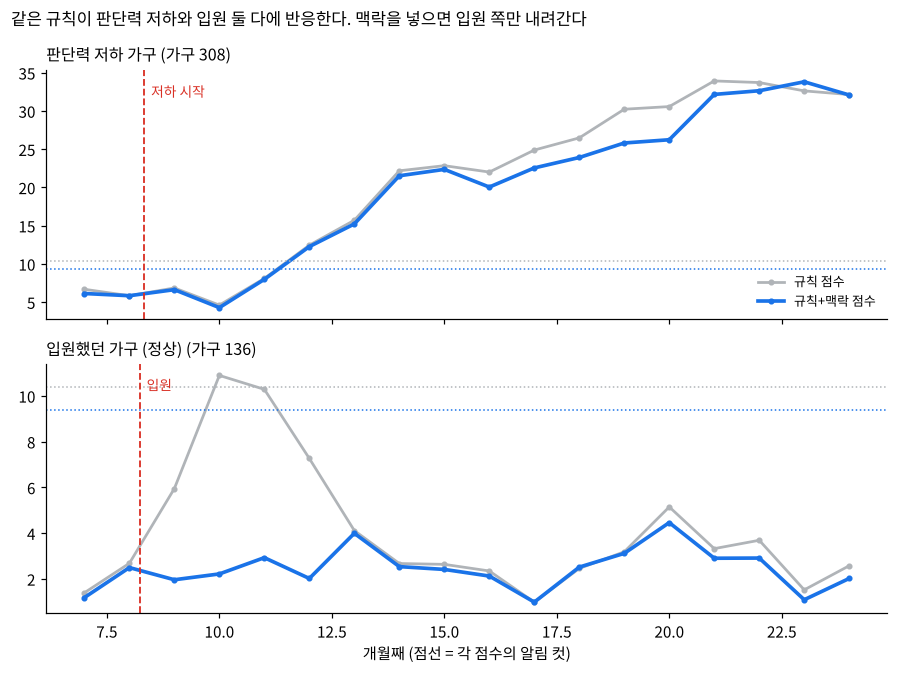

,grp,event_month,first_rule,first_ctx
pid,,,,
136,hospital,8.233333,10,NaN
308,decline,8.333333,12,12.0


In [2]:
ex = pd.read_csv(f"{RES}/decline_examples.csv")
fig, axes = plt.subplots(2, 1, figsize=(8.2, 6.2), sharex=True)
for ax, (pid, title) in zip(axes, [(ex[ex.grp == "decline"].pid.iloc[0], "판단력 저하 가구"), (ex[ex.grp == "hospital"].pid.iloc[0], "입원했던 가구 (정상)")]):
    d = ex[ex.pid == pid]
    ax.plot(d.c + 1, d["규칙"], color=GREY, lw=1.8, marker="o", ms=3, label="규칙 점수")
    ax.plot(d.c + 1, d["규칙+맥락"], color=BLUE, lw=2.4, marker="o", ms=3, label="규칙+맥락 점수")
    ax.axhline(d.cut_rule.iloc[0], color=GREY, ls=":", lw=1); ax.axhline(d.cut_ctx.iloc[0], color=BLUE, ls=":", lw=1)
    ev = d.event_month.iloc[0]
    ax.axvline(ev, color=RED, lw=1.2, ls="--")
    ax.text(ev + 0.15, ax.get_ylim()[1] * 0.9 if ax.get_ylim()[1] > 0 else 1, "저하 시작" if "저하" in title else "입원", color=RED, fontsize=9)
    ax.set_title(f"{title} (가구 {pid})", loc="left", fontsize=10.5); clean(ax)
axes[0].legend(frameon=False, fontsize=8.5, loc="lower right")
axes[1].set_xlabel("개월째 (점선 = 각 점수의 알림 컷)")
fig.suptitle("같은 규칙이 판단력 저하와 입원 둘 다에 반응한다. 맥락을 넣으면 입원 쪽만 내려간다", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()
ex.groupby("pid")[["grp", "event_month", "first_rule", "first_ctx"]].first()

위 가구는 저하가 시작되고 몇 달 동안 점수가 천천히 오르다가 컷을 넘는다. 사기처럼 한 번에 튀지 않는다.

아래 가구는 입원 직후 점수가 급히 오른다. 퇴원 후 밀린 공과금을 몰아서 내서 빠뜨림·중복·납부일 이동이 한꺼번에 잡히기 때문이다. 규칙 점수(회색)는 컷을 넘어 헛알림이 나가지만, 맥락 점수(파랑)는 '직전에 활동 공백이 있었다'는 걸 보고 공과금 신호를 빼서 컷 아래에 머문다.

## 3. 평가

알림 규칙: 매월 말 점수가 컷을 넘으면 그 가구에 '안부 확인 권유' 알림을 한 번 보낸다. 컷은 **판단력 저하가 아닌 가구 중 2년 동안 한 번이라도 알림을 받는 비율**(헛알림 부담)을 2%, 5%, 10%로 맞춰 정한다.

비교한 방법

- **규칙**: 나빠지는 방향의 변화 피처를 0~5로 잘라 더한 값 (라벨 없음)
- **규칙+지속**: 최근 3개월 규칙 점수의 평균. 일시적 변화를 걸러내려는 시도
- **규칙+맥락**: 활동 공백 직후의 공과금 신호를 빼고, 납부일 '이동' 대신 '흐트러짐'을 씀
- **IF**: 변화 피처로 학습한 Isolation Forest (라벨 없음)
- **지도학습(상한)**: 가구 단위 5-fold, 라벨 = 저하 시작 이후. 실제로는 진단 라벨을 거의 얻을 수 없으므로 '라벨이 있다면'의 상한이다

지표: 저하 시작 후 k개월 안에 첫 알림이 나간 비율. 그 시점까지 관측되는 가구만 센다.

In [3]:
R = json.load(open(f"{RES}/results_decline.json"))
rows = [dict(seed=r["seed"], 헛알림부담=float(fa), 모델=m, **v) for r in R for fa, d in r["res"].items() for m, v in d.items()]
D = pd.DataFrame(rows)
ORDER = ["규칙", "규칙+지속", "규칙+맥락", "IF", "지도학습(상한)"]
t = D[D.헛알림부담 == 0.05].groupby("모델")[["det_3m", "det_6m", "det_9m", "det_12m", "lead_median"]].mean().loc[ORDER]
t.columns = ["3개월 안", "6개월 안", "9개월 안", "12개월 안", "알림 시점 중앙값(개월)"]
t.style.format({c: "{:.0%}" for c in t.columns[:4]} | {t.columns[4]: "{:.1f}"})

,3개월 안,6개월 안,9개월 안,12개월 안,알림 시점 중앙값(개월)
모델,,,,,
규칙,2%,56%,98%,100%,5.8
규칙+지속,1%,46%,97%,100%,6.2
규칙+맥락,4%,58%,97%,99%,5.7
IF,0%,6%,65%,97%,8.3
지도학습(상한),14%,89%,99%,100%,4.2


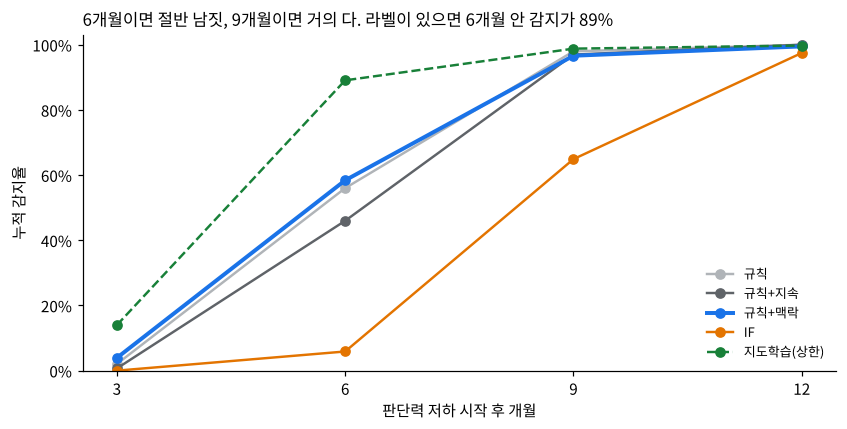

In [4]:
fig, ax = plt.subplots(figsize=(7.8, 4))
col = {"규칙": GREY, "규칙+지속": DARK, "규칙+맥락": BLUE, "IF": ORANGE, "지도학습(상한)": GREEN}
m = D[D.헛알림부담 == 0.05].groupby("모델")[["det_3m", "det_6m", "det_9m", "det_12m"]].mean()
for k in ORDER:
    ax.plot([3, 6, 9, 12], m.loc[k], marker="o", color=col[k], lw=2.6 if k == "규칙+맥락" else 1.6,
            ls="--" if "상한" in k else "-", label=k)
ax.set_xticks([3, 6, 9, 12]); ax.set_xlabel("판단력 저하 시작 후 개월")
ax.set_ylim(0, 1.03); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax.set_ylabel("누적 감지율")
ax.set_title("6개월이면 절반 남짓, 9개월이면 거의 다. 라벨이 있으면 6개월 안 감지가 89%", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8.5, loc="lower right"); clean(ax); plt.tight_layout(); plt.show()

- **첫 3개월은 누구도 잘 못 잡는다.** 진행도가 아직 0.1~0.3이라 정상 가구의 평소 실수와 구분이 안 된다. 거래 데이터만으로 '아주 이른' 감지는 어렵다는 게 정직한 결론이다.
- 규칙은 6개월 안에 절반 남짓, 9개월 안에 거의 다 잡는다.
- **규칙+지속은 오히려 늦다.** 3개월 평균을 내면 일시적 변화도 줄지만 진짜 신호도 3개월 늦게 반영된다. 지속성으로 걸러내는 대신 '왜 변했는지'(맥락)를 보는 게 낫다.
- **IF는 거의 못 잡는다.** 라벨 없이 '드문 가구'를 찾으면, 입원·합가처럼 변화가 큰 가구가 먼저 걸린다. 판단력 저하는 '크게' 변하는 게 아니라 '여러 곳에서 조금씩' 변한다. 무엇이 나빠지는 방향인지 아는 규칙(도메인 지식)이 여기서 이긴다.
- 지도학습은 6개월 안에 약 89%, 알림 시점 중앙값은 약 4.2개월. 규칙+맥락과의 차이 약 30%p가 진단 라벨의 가치다.

### 헛알림은 누구에게 가나

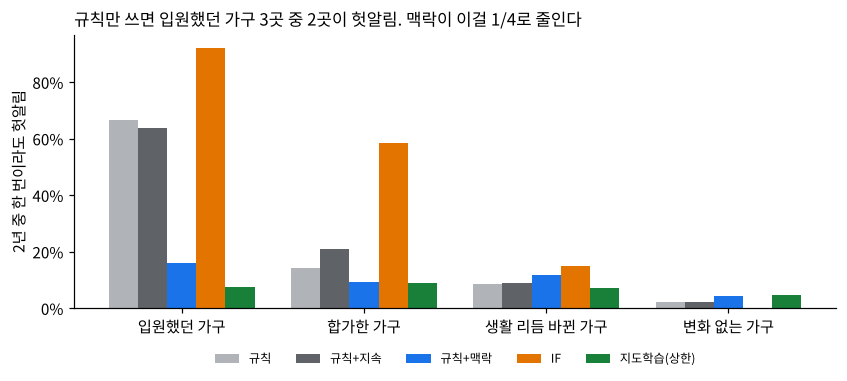

,입원했던 가구,합가한 가구,생활 리듬 바뀐 가구,변화 없는 가구
모델,,,,
규칙,66%,14%,9%,2%
규칙+지속,64%,21%,9%,2%
규칙+맥락,16%,9%,12%,4%
IF,92%,58%,15%,0%
지도학습(상한),8%,9%,7%,5%


In [5]:
fa = D[D.헛알림부담 == 0.05].groupby("모델")[["fa_hospital", "fa_move_in", "fa_new_routine", "fa_normal"]].mean().loc[ORDER]
fa.columns = ["입원했던 가구", "합가한 가구", "생활 리듬 바뀐 가구", "변화 없는 가구"]
fig, ax = plt.subplots(figsize=(7.8, 3.6))
x = np.arange(len(fa.columns)); w = 0.16
for i, k in enumerate(ORDER):
    ax.bar(x + (i - 2) * w, fa.loc[k], w, color=col[k], label=k)
ax.set_xticks(x); ax.set_xticklabels(fa.columns); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.set_ylabel("2년 중 한 번이라도 헛알림")
ax.set_title("규칙만 쓰면 입원했던 가구 3곳 중 2곳이 헛알림. 맥락이 이걸 1/4로 줄인다", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12)); clean(ax); plt.tight_layout(); plt.show()
fa.style.format("{:.0%}")

전체 헛알림 부담(5%)은 같게 맞췄으니, 차이는 **헛알림이 누구에게 가느냐**다.

- 규칙은 헛알림 대부분을 입원했던 가구에 쓴다. 이 가족들은 입원 사실을 이미 안다. "부모님 결제 패턴이 달라졌어요"라는 알림은 쓸모없고 서비스 신뢰만 깎는다.
- 맥락을 넣으면 입원 가구 헛알림이 약 67% → 16%로 줄고, 감지율은 그대로다(6개월 안 56% → 58%). 대신 헛알림 일부가 변화 없는 가구와 생활 리듬이 바뀐 가구로 옮겨 간다. 전체 예산이 같으니 당연하다.
- 지도학습은 입원과 저하를 거의 구분한다. 라벨이 있으면 '무엇이 저하가 아닌지'도 배우기 때문이다.

In [6]:
s = D.groupby(["헛알림부담", "모델"])[["det_6m", "det_9m", "fa_hospital"]].mean().unstack(0)
s = s.loc[ORDER]
s.columns = [f"{a} @{b:.0%}" for a, b in s.columns]
s.style.format("{:.0%}")

,det_6m @2%,det_6m @5%,det_6m @10%,det_9m @2%,det_9m @5%,det_9m @10%,fa_hospital @2%,fa_hospital @5%,fa_hospital @10%
모델,,,,,,,,,
규칙,39%,56%,68%,93%,98%,98%,42%,66%,82%
규칙+지속,28%,46%,57%,92%,97%,98%,40%,64%,82%
규칙+맥락,43%,58%,66%,94%,97%,98%,10%,16%,21%
IF,0%,6%,33%,8%,65%,93%,57%,92%,99%
지도학습(상한),84%,89%,92%,99%,99%,98%,3%,8%,13%


헛알림 부담을 2%로 낮추면 6개월 안 감지가 약 4할로, 10%로 높이면 약 7할로 바뀐다. 이 숫자로 서비스 정책을 정한다. '2년에 한 번 정도 헛알림'을 감수할 가족이 얼마나 되는지가 실제 운영의 기준이 된다.

## 4. 설계에 주는 의미

**알림은 두 종류로 나눠야 한다.**

| | 사기 알림 (v2~v4) | 생활 변화 알림 (v5) |
| --- | --- | --- |
| 긴급도 | 지금 바로 (분·시간 단위) | 몇 주 안에 |
| 문구 | "처음 보는 계좌로 평소의 15배 송금. 확인해 보세요" | "최근 3개월 공과금 납부가 자주 밀리고 같은 결제가 반복돼요. 안부 전화 한 번 해보세요" |
| 근거 제시 | 거래 한 건 | 바뀐 신호 목록과 기준선 대비 변화 |
| 다음 단계 | 지연이체·지급정지 | 치매안심센터 안내, 자동이체 정리, 성년후견·신탁 상담 |

**라벨 전략.** 규칙과 지도학습의 차이(6개월 안 약 58% vs 89%)를 줄이려면 진단 라벨이 필요하다. 거래 데이터만으로는 얻을 수 없으니, 서비스 안에서 가족이 "실제로 진단을 받았다", "아니다, 이사했다"를 답할 수 있게 하고(동의 기반), 그 응답을 라벨로 쓴다. 생활 변화(입원·합가)를 가족이 미리 알려줄 수 있게 하면 그 자체로 맥락 피처가 된다.

**조심할 점.** 이 알림은 '치매 진단'이 아니다. 문구에 질병명을 쓰지 않고, 관찰된 행동 변화만 전달한다. 본인 동의 없이 가족에게 건강 관련 추정을 알리는 건 개인정보·인권 측면에서 문제가 될 수 있어서, 가입 단계에서 본인 동의를 받는 설계가 전제다.

## 5. 한계

- 판단력 저하의 거래 신호(빠뜨림, 중복, 밤 거래 등)와 그 크기는 직접 설계한 가정이다. 실제 연구 데이터로 검증하지 않았다.
- 판단력 저하 가구는 모두 '진행'하고, 생활 변화는 세 종류뿐이다. 실제로는 우울·사별·경제 사정 같은 더 다양한 변화가 섞인다.
- 기준선 6개월이 이미 저하가 시작된 뒤라면(가입 시점에 이미 진행 중) 이 방법은 변화를 못 본다. 그런 가구는 동년배 집단과 비교하는 방식이 따로 필요하다.